In [2]:
from pathlib import Path
import pyart

path = Path('/Volumes/Rain/LaCie/projDir/data/mdv/radarPolar/ops/sur/20181209/000848.mdv')

radar = pyart.io.read_mdv(str(path))

print('Fields:', list(radar.fields.keys()))
print('Latitude:', radar.latitude['data'])
print('Longitude:', radar.longitude['data'])
print('Altitude:', radar.altitude['data'])

for field in radar.fields:
    print(
        field,
        radar.fields[field]['data'].shape,
        radar.fields[field].get('units')
    )

Fields: ['normalized_coherent_power', 'spectrum_width', 'differential_reflectivity', 'differential_phase', 'cross_correlation_ratio', 'velocity', 'specific_differential_phase', 'reflectivity']
Latitude: [-2.15807605]
Longitude: [30.11234093]
Altitude: [1616.00005627]
normalized_coherent_power (3960, 1042) ratio
spectrum_width (3960, 1042) meters_per_second
differential_reflectivity (3960, 1042) dB
differential_phase (3960, 1042) degrees
cross_correlation_ratio (3960, 1042) ratio
velocity (3960, 1042) meters_per_second
specific_differential_phase (3960, 1042) degrees/km
reflectivity (3960, 1042) dBZ


In [3]:
radar = pyart.io.read_mdv(str(path))

print('Number of sweeps:', radar.nsweeps)
print('Sweep elevations:', radar.fixed_angle['data'])
print('Radar altitude:', radar.altitude['data'])

Number of sweeps: 11
Sweep elevations: [ 0.5  1.5  2.5  3.5  4.5  6.   8.  11.  15.  22.  32. ]
Radar altitude: [1616.00005627]


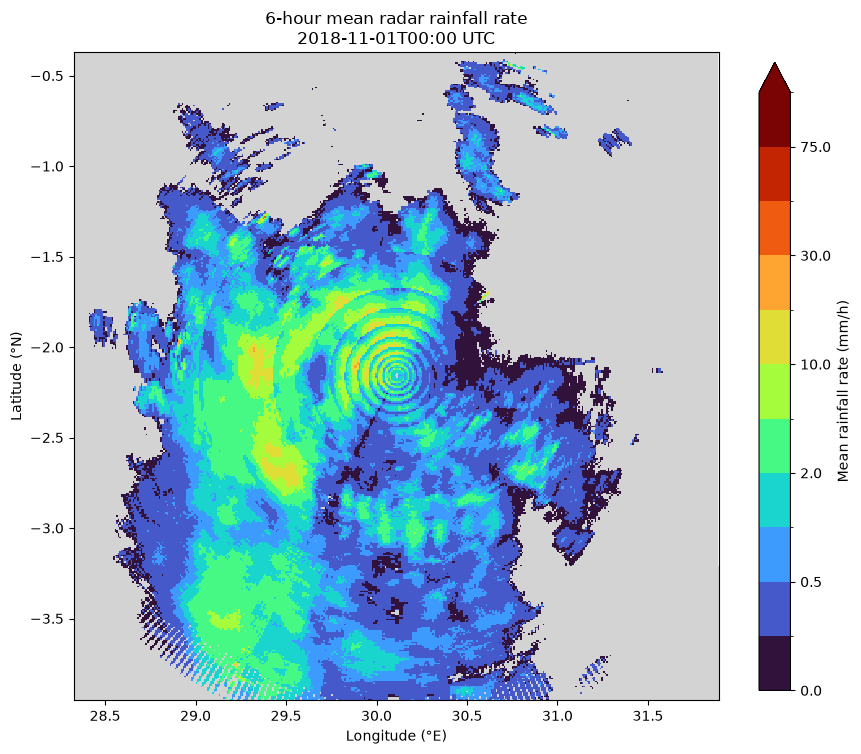

Valid pixels: 76653
Valid fraction: 0.4888085399449036
Minimum rainfall rate: 0.0 mm/h
Maximum rainfall rate: 30.629812 mm/h
Mean rainfall rate: 1.3432989 mm/h


In [4]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import BoundaryNorm

# Load 6-hour mean rainfall rate
nc_file = Path(
    '/Users/matthewwright/Downloads/test_mdv_files_simple/20181101_00.nc'
)

with xr.open_dataset(nc_file) as ds:
    rain = ds['rainfall_rate'].load()
    lat = ds['lat'].values
    lon = ds['lon'].values
    time = ds['time'].values

# Plot
fig, ax = plt.subplots(figsize=(9, 8))

levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100]
cmap = plt.get_cmap('turbo', len(levels) - 1).copy()
cmap.set_bad('lightgrey')

norm = BoundaryNorm(levels, cmap.N)

mesh = ax.pcolormesh(
    lon, lat, rain.values,
    cmap=cmap,
    norm=norm,
    shading='auto'
)

cbar = plt.colorbar(mesh, ax=ax, extend='max', shrink=0.85)
cbar.set_label('Mean rainfall rate (mm/h)')

ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title(
    f'6-hour mean radar rainfall rate\n'
    f'{np.datetime_as_string(time, unit="m")} UTC'
)

ax.set_aspect('equal')
plt.tight_layout()
plt.show()

# Basic statistics
values = rain.values

print('Valid pixels:', np.isfinite(values).sum())
print('Valid fraction:', np.isfinite(values).mean())
print('Minimum rainfall rate:', np.nanmin(values), 'mm/h')
print('Maximum rainfall rate:', np.nanmax(values), 'mm/h')
print('Mean rainfall rate:', np.nanmean(values), 'mm/h')

20181101_00.nc | valid: 83062 | max: 58.35 | mean: 0.91 mm/h
20181101_06.nc | valid: 92111 | max: 127.61 | mean: 2.81 mm/h
20181101_12.nc | valid: 100313 | max: 105.36 | mean: 1.96 mm/h
20181101_18.nc | valid: 96344 | max: 59.2 | mean: 0.39 mm/h


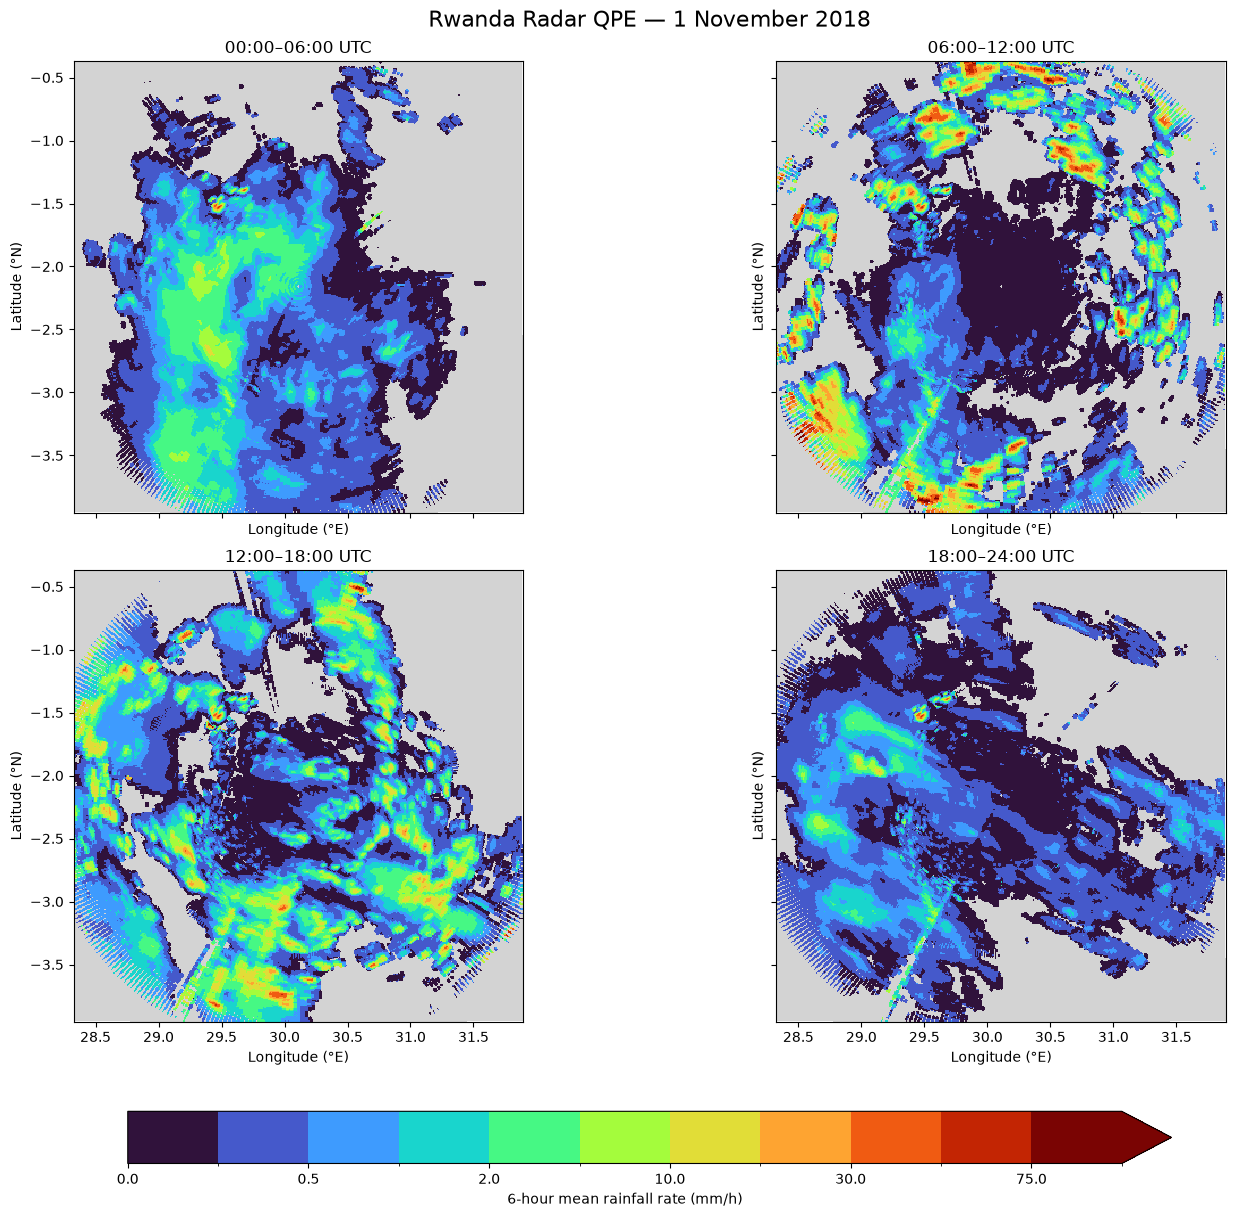

In [5]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import BoundaryNorm

OUTPUT_DIR = Path('/Volumes/Rain/rwanda_mdv_to_qpe')

files = sorted(OUTPUT_DIR.glob('20181101_*.nc'))

levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100]
cmap = plt.get_cmap('turbo', len(levels) - 1).copy()
cmap.set_bad('lightgrey')
norm = BoundaryNorm(levels, cmap.N)

fig, axes = plt.subplots(
    2, 2, figsize=(14, 12),
    sharex=True, sharey=True,
    constrained_layout=True
)

for ax, file in zip(axes.flat, files):
    with xr.open_dataset(file) as ds:
        rain = ds['rainfall_rate'].values
        lat = ds['lat'].values
        lon = ds['lon'].values

    mesh = ax.pcolormesh(
        lon, lat, rain,
        cmap=cmap,
        norm=norm,
        shading='auto'
    )

    ax.set_title(
        f'{file.stem[-2:]}:00–{(int(file.stem[-2:]) + 6):02d}:00 UTC'
    )
    ax.set_xlabel('Longitude (°E)')
    ax.set_ylabel('Latitude (°N)')
    ax.set_aspect('equal')

    print(
        file.name,
        '| valid:', np.isfinite(rain).sum(),
        '| max:', round(float(np.nanmax(rain)), 2),
        '| mean:', round(float(np.nanmean(rain)), 2),
        'mm/h'
    )

for ax in axes.flat[len(files):]:
    ax.set_visible(False)

fig.colorbar(
    mesh,
    ax=axes,
    orientation='horizontal',
    shrink=0.75,
    pad=0.04,
    extend='max',
    label='6-hour mean rainfall rate (mm/h)'
)

fig.suptitle(
    'Rwanda Radar QPE — 1 November 2018',
    fontsize=16
)

plt.show()

In [11]:
import os
import psutil

print('Logical CPUs:', os.cpu_count())
print('Physical CPU cores:', psutil.cpu_count(logical=False))
print('Available RAM:', round(psutil.virtual_memory().available / 1e9, 2), 'GB')
print('Total RAM:', round(psutil.virtual_memory().total / 1e9, 2), 'GB')

Logical CPUs: 10
Physical CPU cores: 10
Available RAM: 4.9 GB
Total RAM: 17.18 GB


In [12]:
import os
import psutil

physical = psutil.cpu_count(logical=False)
logical = os.cpu_count()
available_ram = psutil.virtual_memory().available / 1e9

print(f'Physical cores: {physical}')
print(f'Logical CPUs: {logical}')
print(f'Available RAM: {available_ram:.1f} GB')

# Conservative starting point
recommended = min(physical or logical or 2, 8)

print(f'Suggested starting N_WORKERS: {recommended}')

Physical cores: 10
Logical CPUs: 10
Available RAM: 5.0 GB
Suggested starting N_WORKERS: 8
